In [1]:
import os
import csv
import numpy as np
import skgstat as skg
import geopandas as gpd
import pandas as pd 


In [2]:
dataframe = pd.read_csv("../Data/unitask_data/dataset.csv")
# Determining features and target columns
columns = dataframe.columns.to_list()
soil_properties = ['pH', 'CE', 'CEC', 'OM', 'A%', 'L%', 'S%']
cols_to_drop = soil_properties + ['X', 'Y']
covariates = [col for col in columns if col not in cols_to_drop]

In [3]:
gdf = gpd.GeoDataFrame(
    dataframe,
    geometry=gpd.points_from_xy(dataframe['X'], dataframe['Y']),
    crs='EPSG:4326'
)

gdf = gdf.to_crs('EPSG:32631')

points = np.column_stack((gdf.geometry.x, gdf.geometry.y))
print("Points shape:", points)

Points shape: [[ 228647.80536118 3970092.37869411]
 [ 228647.80536118 3970092.37869411]
 [ 228562.59435703 3967318.38481283]
 ...
 [ 945565.02894445 4089436.00319456]
 [ 963062.49605393 4096869.05213493]
 [ 975698.18047024 4097568.48396603]]


## Spatial Autocorrelation using simple span 

In [4]:
x_span = gdf.geometry.x.max() - gdf.geometry.x.min()
y_span = gdf.geometry.y.max() - gdf.geometry.y.min()
print("X range:", gdf.geometry.x.min(), "-", gdf.geometry.x.max(), "(span:", x_span, ")")
print("Y range:", gdf.geometry.y.min(), "-", gdf.geometry.y.max(), "(span:", y_span, ")")

X range: -140840.2152013185 - 975698.1804702375 (span: 1116538.395671556 )
Y range: 2957867.288736204 - 4097568.4839660334 (span: 1139701.1952298293 )


In [5]:
# Spatial block size (grid-based block_cv) and AHC distance threshold
# (sp1_cv), derived from the coordinate spans printed above.
BLOCK_SP_THRESHOLD = max(x_span, y_span) / 10.0   # ~10 blocks across the longer axis
SP1_THRESHOLD = max(x_span, y_span) / 50.0        # finer AHC blocks, then randomly grouped into folds

print(f"BLOCK_SP_THRESHOLD = {BLOCK_SP_THRESHOLD/1000:.0f} km")
print(f"SP1_THRESHOLD = {SP1_THRESHOLD/1000:.0f} km")

BLOCK_SP_THRESHOLD = 114 km
SP1_THRESHOLD = 23 km


## Spatial autocorrelation using skgstat by property  

               pH          CE        CEC          OM          A%          L%  \
50 km   49.995134   40.657209  49.995134   49.995134   49.995134   49.995134   
100 km  99.996504   99.996504  32.449557   99.996504   75.945430   99.996504   
150 km  79.307899  149.997731  34.387213  149.997731  149.997731  149.997731   
200 km  57.662926  199.999998  46.099312  147.331142  199.999998  111.503275   
250 km  61.062336  249.999098  36.744467  109.421324  249.999098   97.597398   
300 km  75.862276  299.999303  64.477334  299.999303  299.999303   86.581477   
400 km  68.056274  399.997123  39.915080  136.469046  399.997123   77.322256   

                S%  
50 km    49.995134  
100 km   99.996504  
150 km  149.997731  
200 km  178.587662  
250 km  221.928803  
300 km  155.807367  
400 km  131.876832  


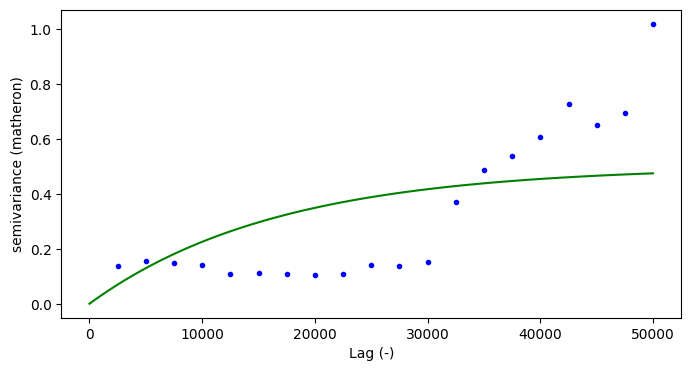

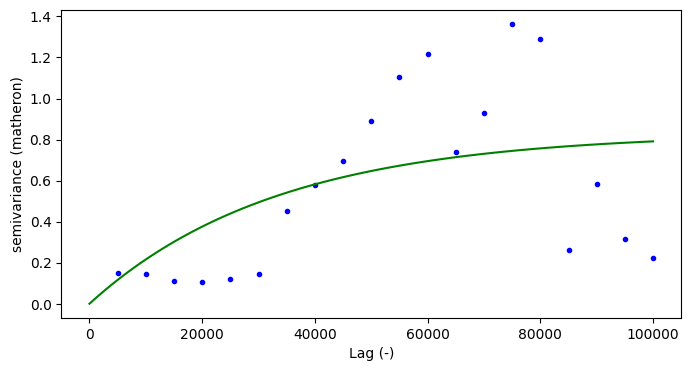

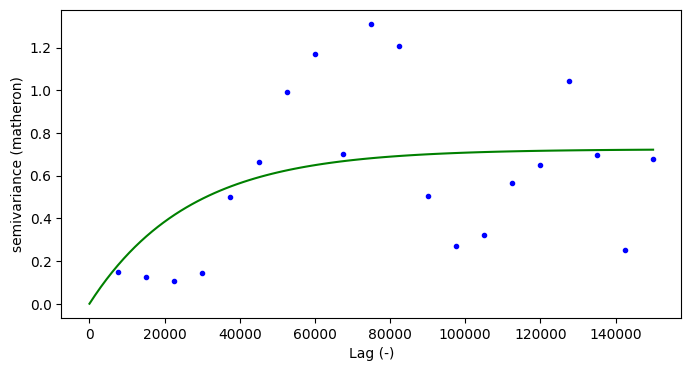

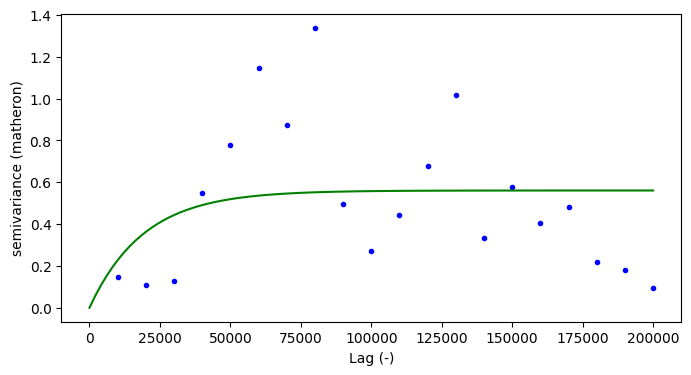

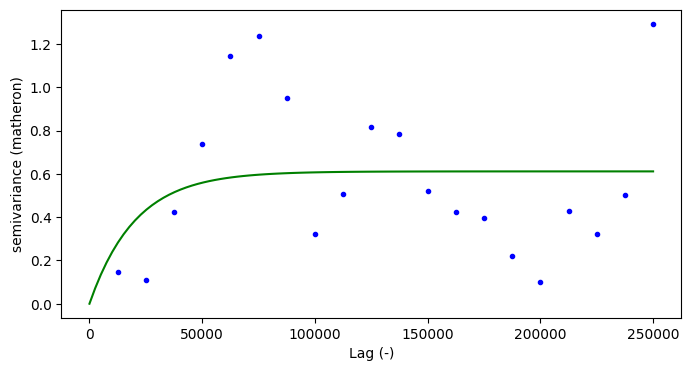

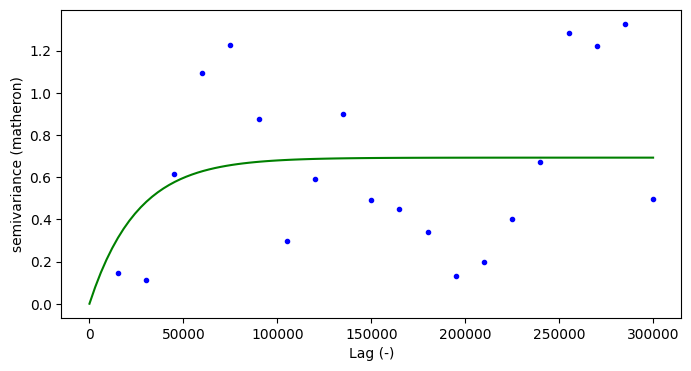

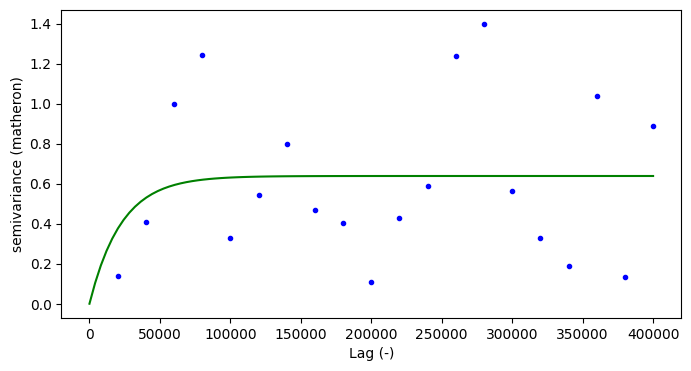

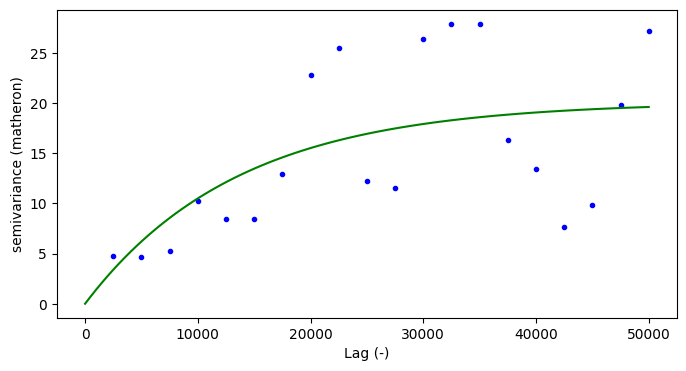

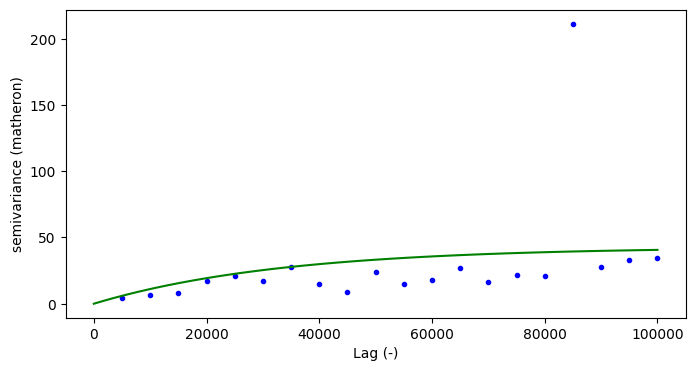

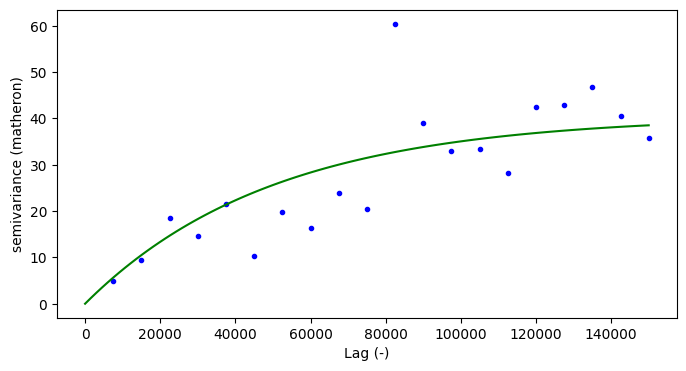

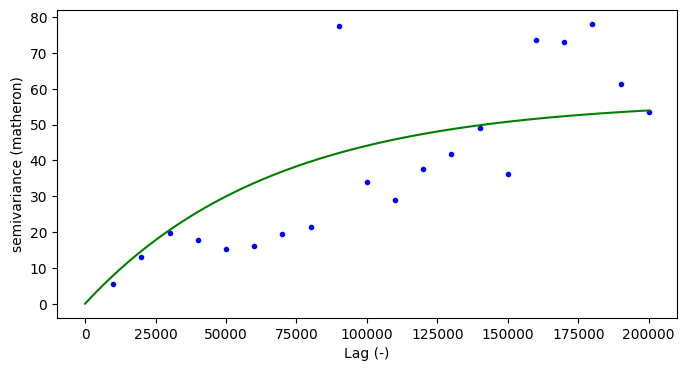

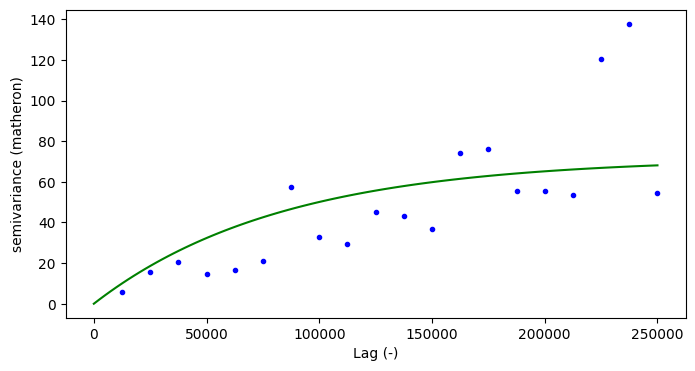

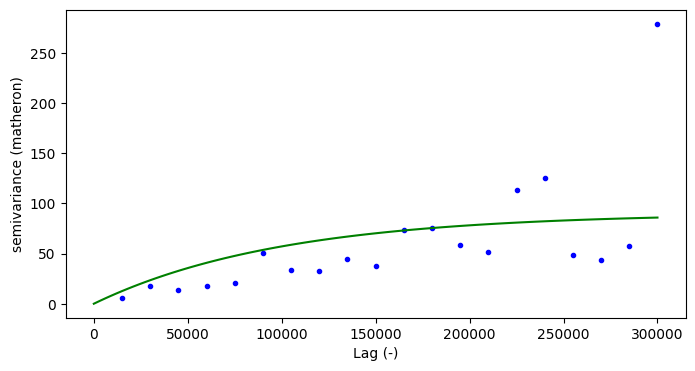

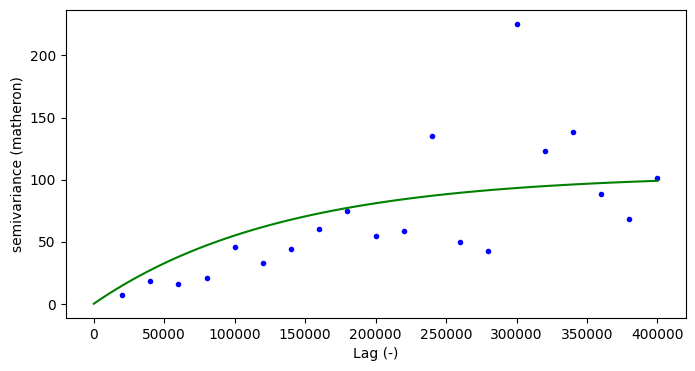

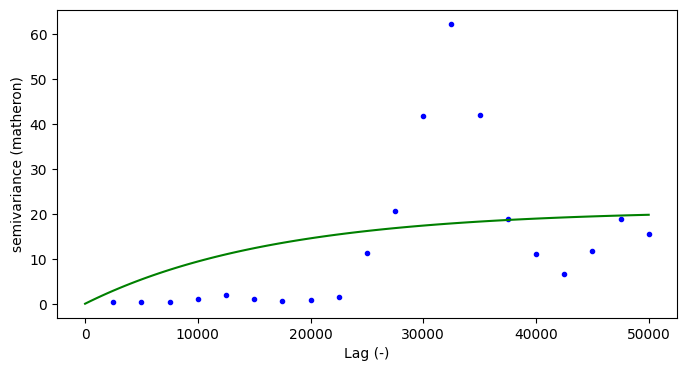

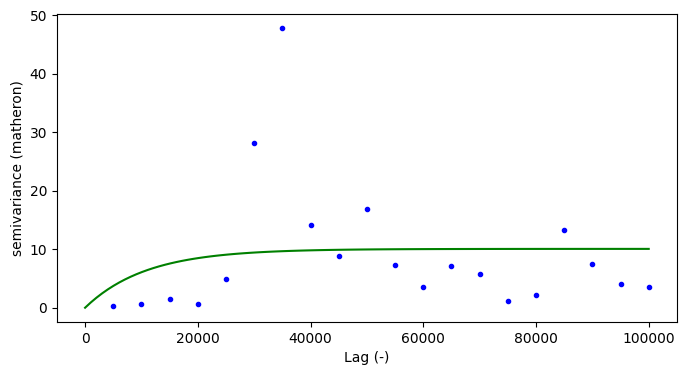

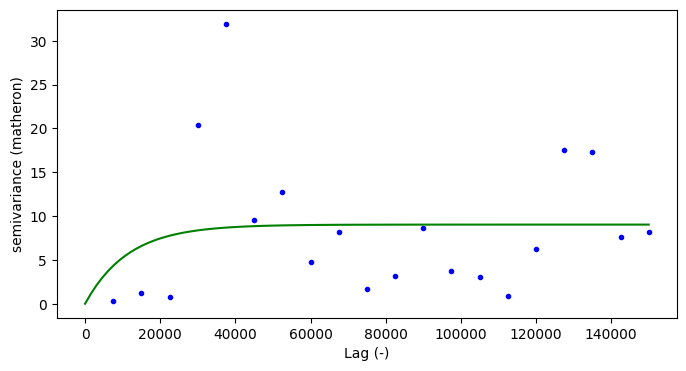

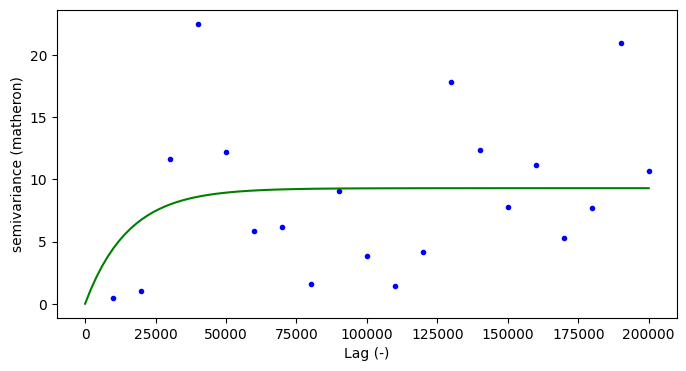

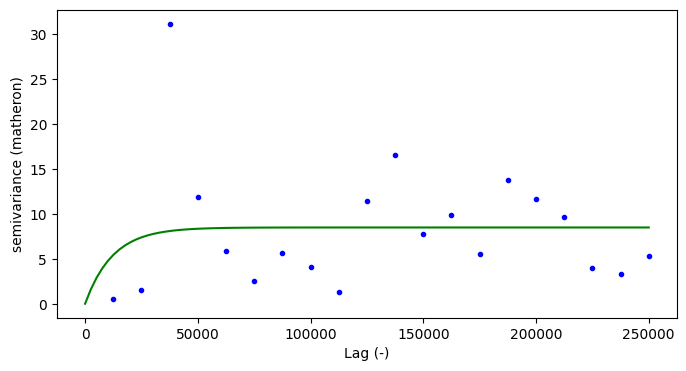

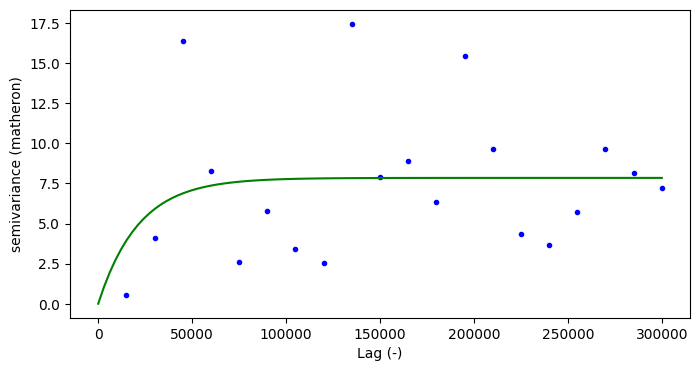

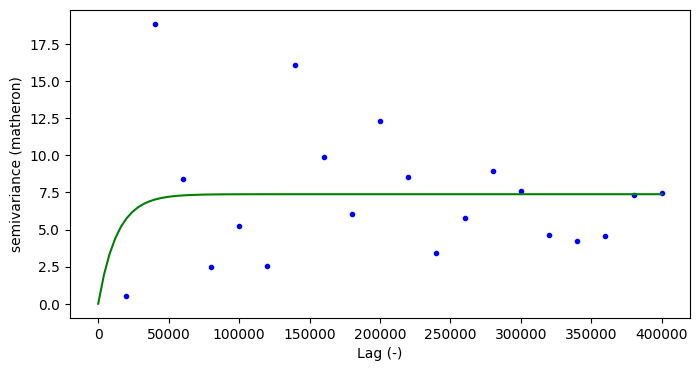

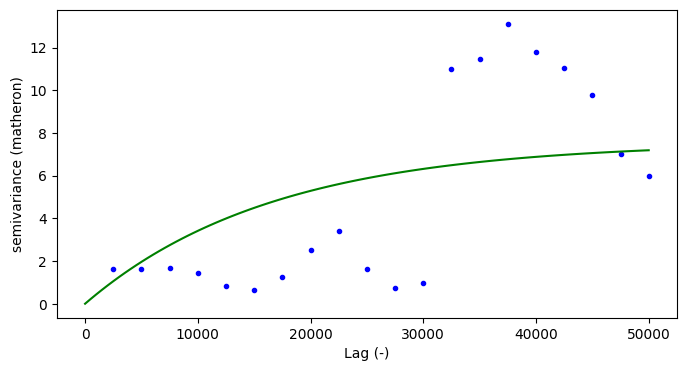

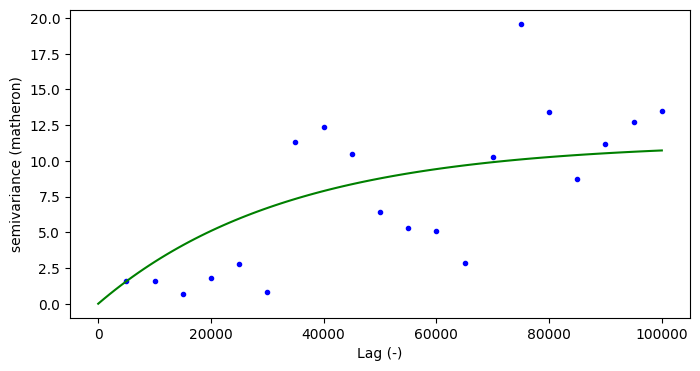

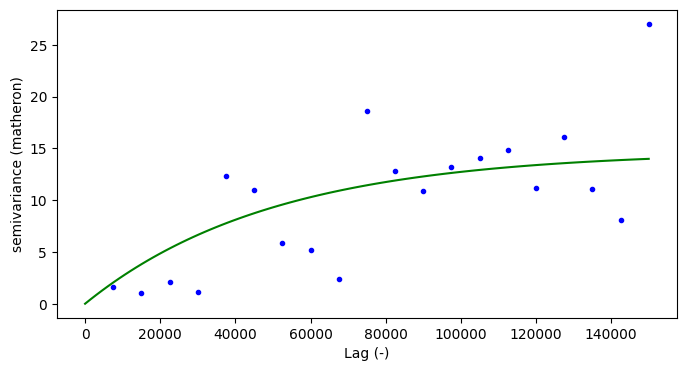

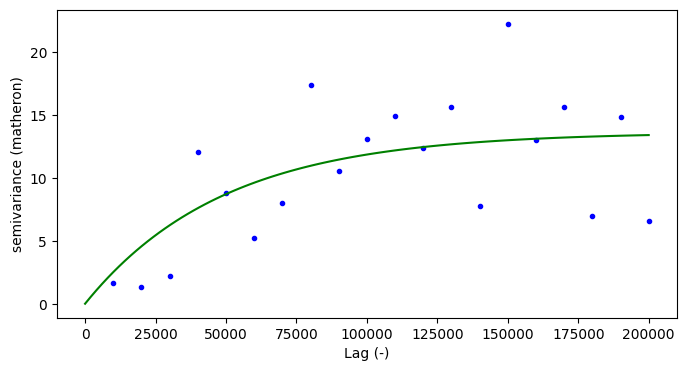

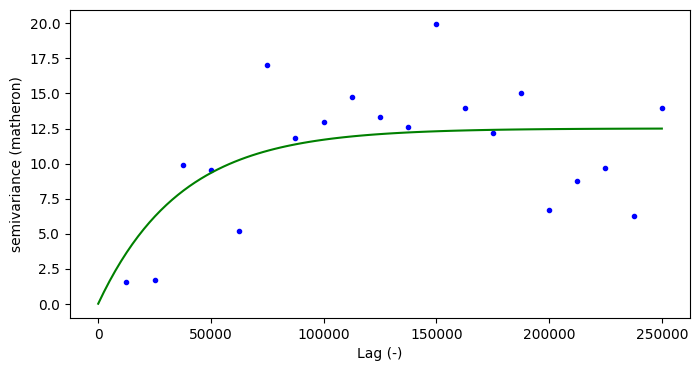

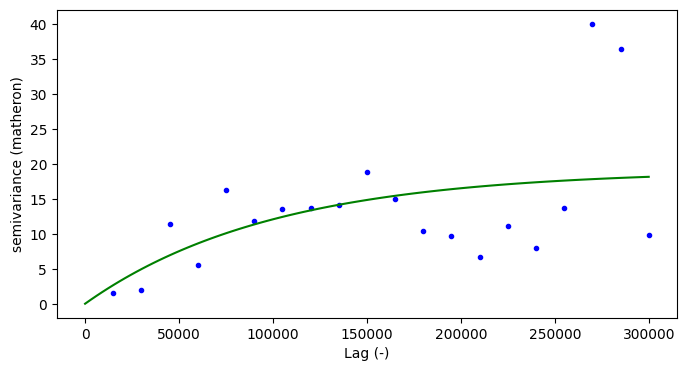

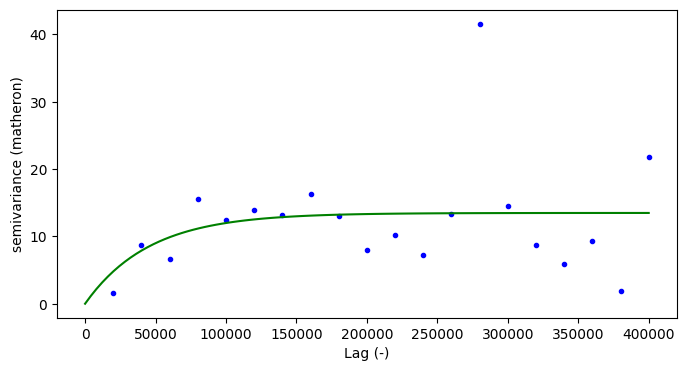

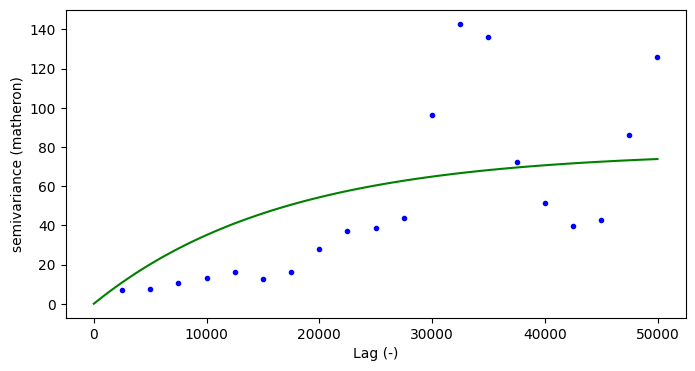

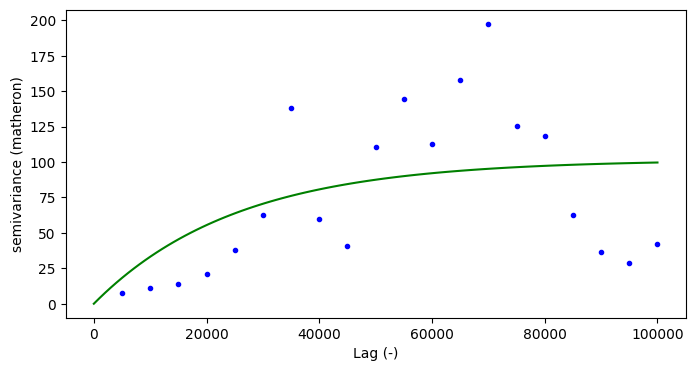

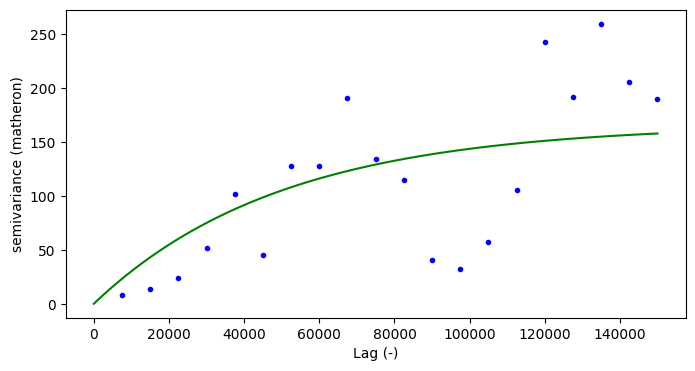

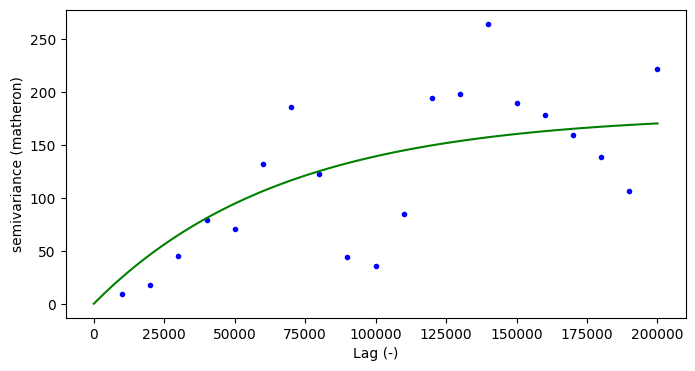

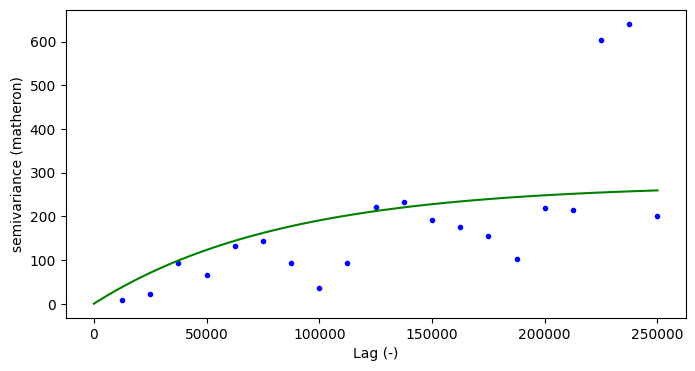

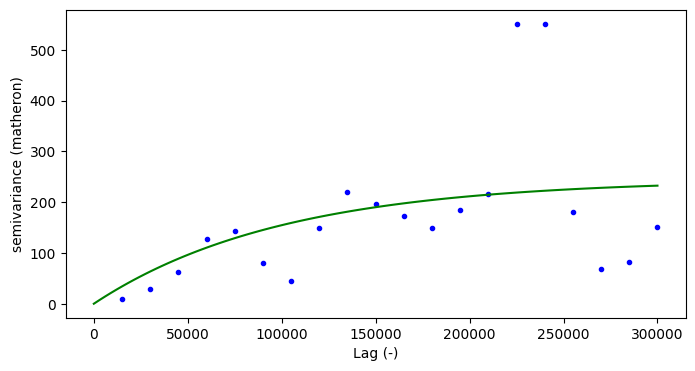

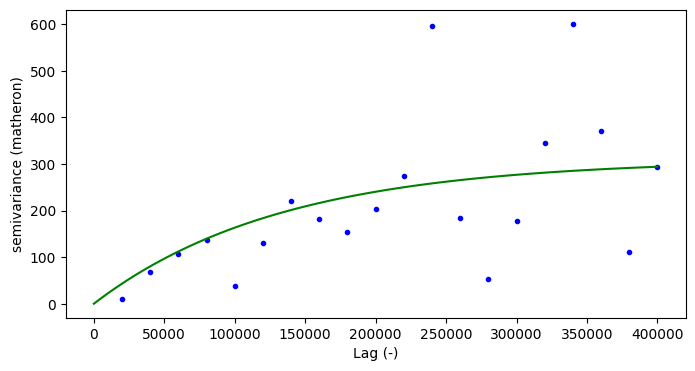

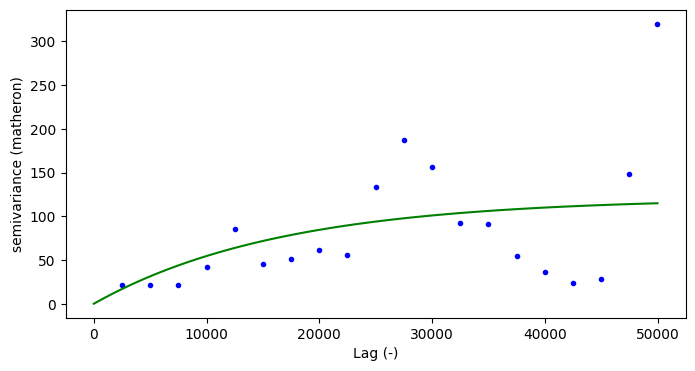

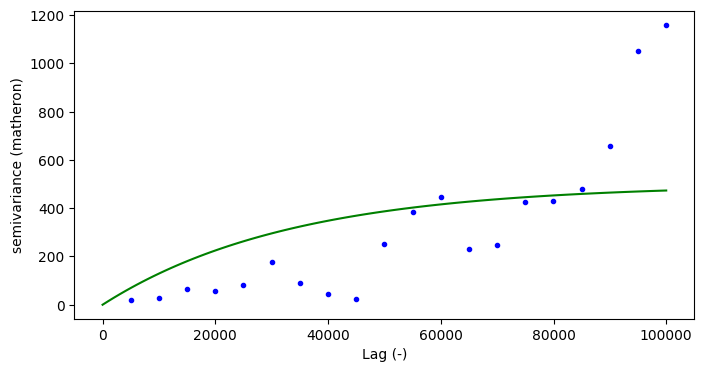

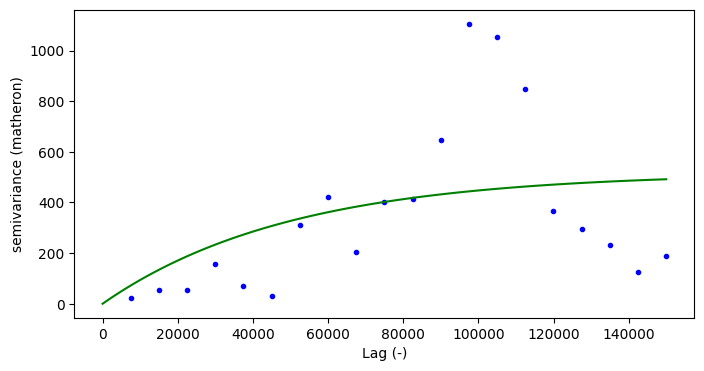

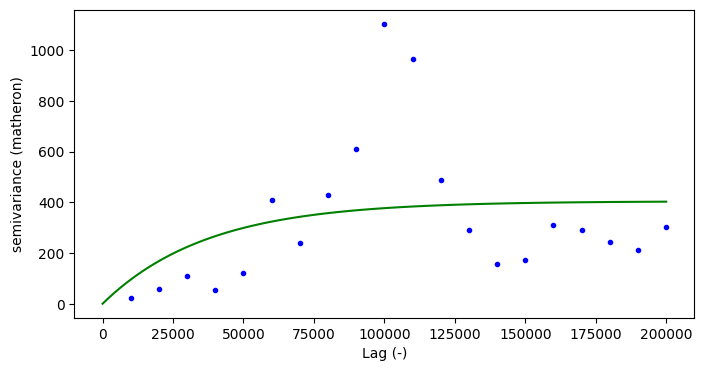

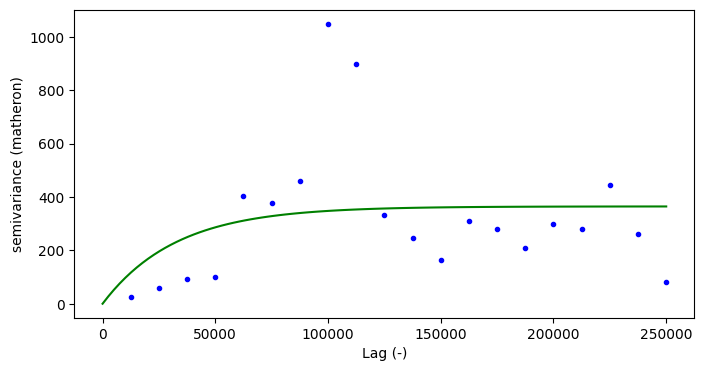

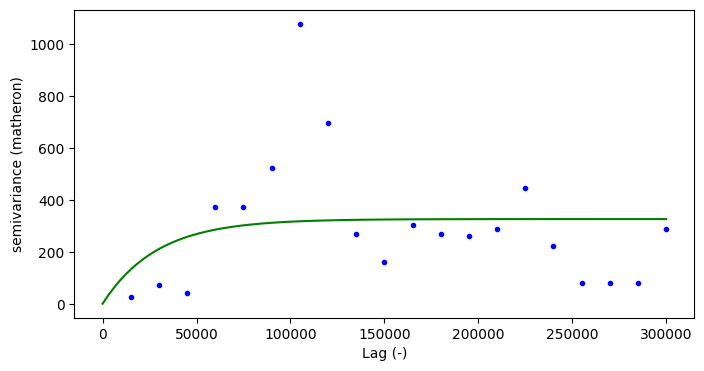

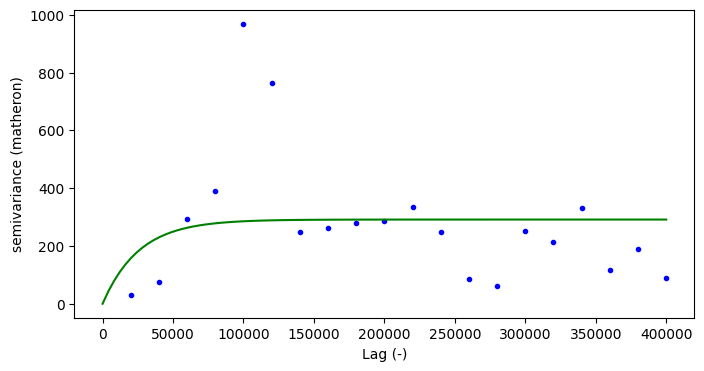

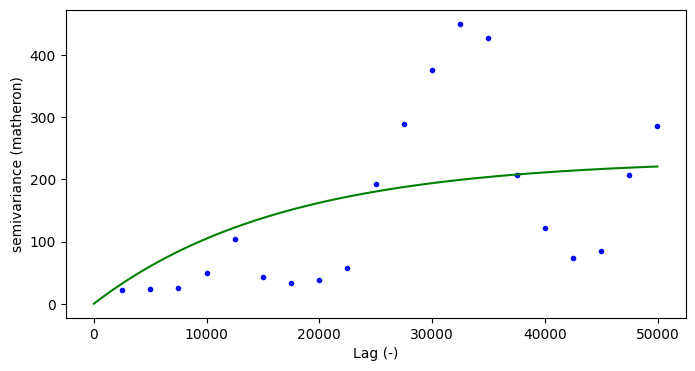

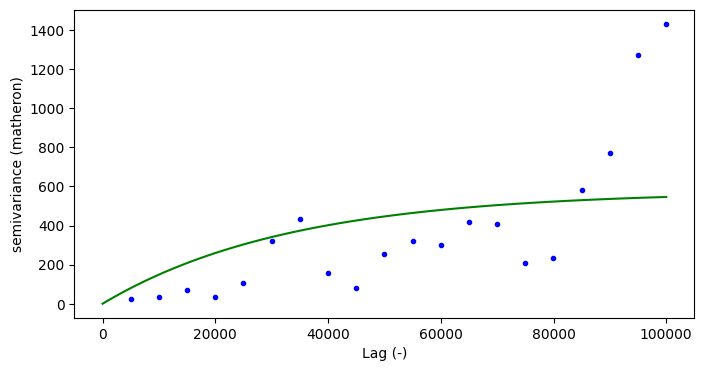

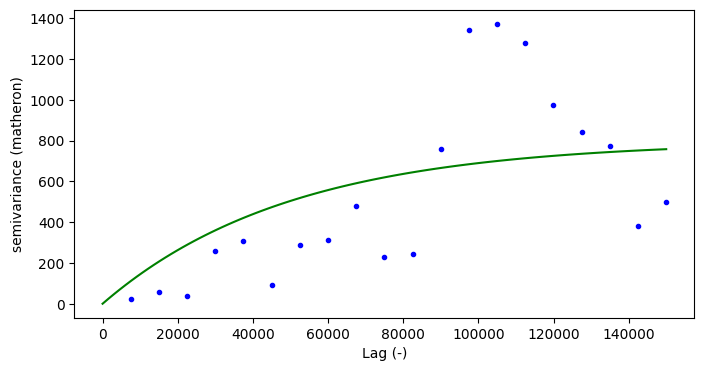

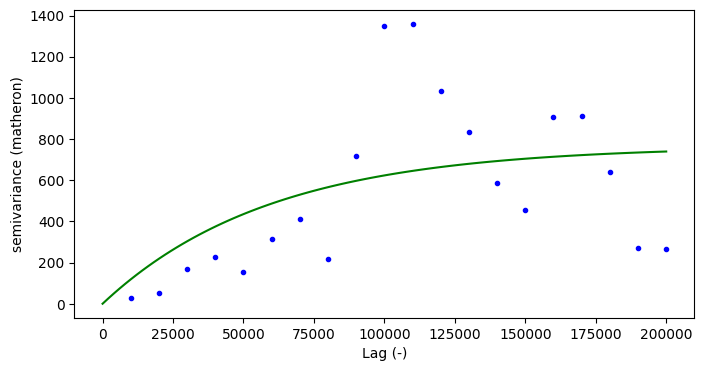

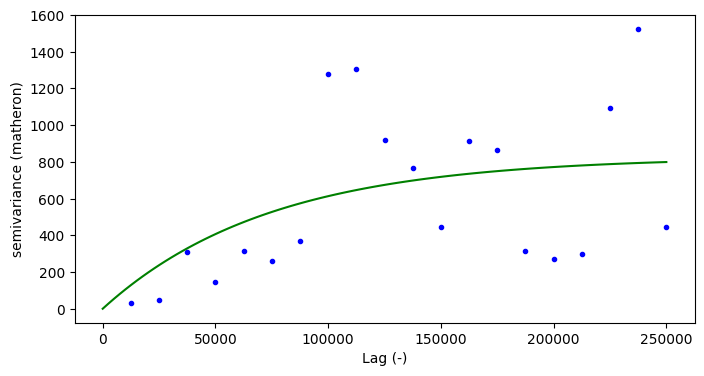

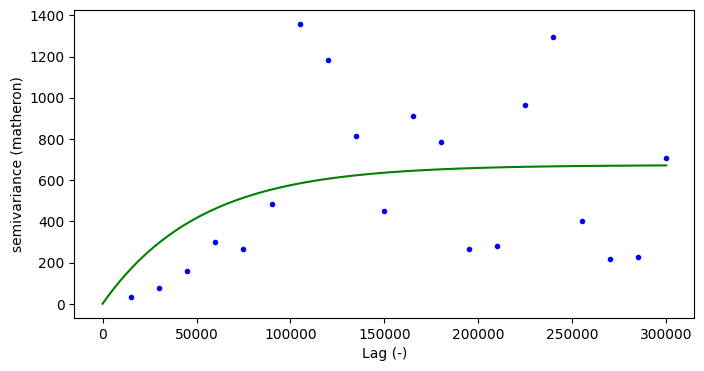

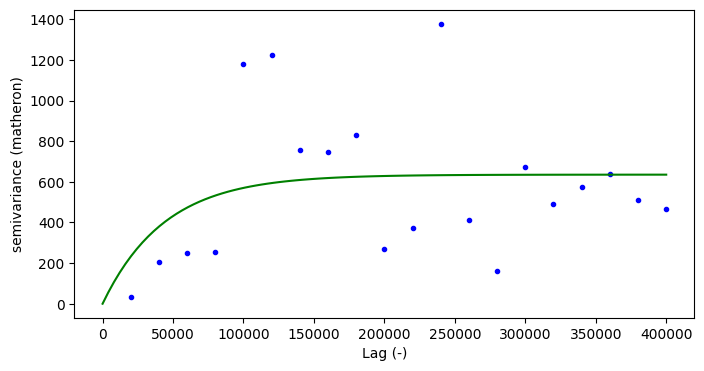

In [6]:
def autocol_threshold(points, tar_values, lag_num, lag_max):
    variogram = skg.Variogram(coordinates = points, values = tar_values, model = 'exponential',
                              n_lags = lag_num, maxlag = lag_max)
    v_fig = variogram.plot(grid = False, hist = False)
    sp_threshold = variogram.parameters[0]
    return sp_threshold, v_fig


maxlags = [50_000, 100_000, 150_000, 200_000, 250_000, 300_000, 400_000]

results = {}

for prop in soil_properties:

    results[prop] = []

    for maxlag in maxlags:

        try:
            threshold, _ = autocol_threshold(
                points,
                dataframe[prop].values,
                lag_num=20,
                lag_max=maxlag
            )

            results[prop].append(threshold / 1000)

        except Exception as e:
            results[prop].append(np.nan)

import pandas as pd

results_df = pd.DataFrame(
    results,
    index=[f"{x/1000:.0f} km" for x in maxlags]
)

print(results_df)

In [8]:
import numpy as np
import pandas as pd
import skgstat as skg


def estimate_spatial_range(
    points,
    value_col,
    coords,
    x_col,
    y_col,
    maxlag=None,
    n_lags=30,
    model="exponential"
):
    """
    Estimate the effective spatial range of a soil property
    using an empirical/theoretical variogram.

    Parameters
    ----------
    points : np.ndarray or pd.DataFrame
        Dataset containing coordinates and soil property.

    value_col : int or str
        Column containing the soil property.

    x_col : int or str
        X coordinate column.

    y_col : int or str
        Y coordinate column.

    maxlag : float or None
        Maximum lag distance in coordinate units.
        If None, automatically estimated.

    n_lags : int
        Number of variogram lag classes.

    model : str
        Variogram model.

    Returns
    -------
    range_value : float
        Estimated effective spatial range.
    """

    if isinstance(points, pd.DataFrame):

        # coords = points[[x_col, y_col]].values
        values = points[value_col].values

    else:

        # coords = points[:, [x_col, y_col]]
        values = points[:, value_col]

    # Remove missing values
    valid = np.isfinite(values)

    coords = coords[valid]
    values = values[valid]

    # Variogram
    V = skg.Variogram(
        coords,
        values,
        model=model,
        n_lags=n_lags,
        maxlag=maxlag,
        normalize=False
    )

    # scikit-gstat estimated effective range
    description = V.describe()

    effective_range = description["effective_range"]

    return effective_range


ranges = []

for prop in soil_properties:

    r = estimate_spatial_range(
        points=dataframe,
        value_col=prop,
        coords = points, 
        x_col="X",
        y_col="Y",
        maxlag=200_000,
        n_lags=30,
        model="exponential"
    )

    ranges.append({
        "property": prop,
        "range_m": r,
        "range_km": r / 1000
    })


ranges_df = pd.DataFrame(ranges)

print(ranges_df)

  property        range_m    range_km
0       pH   55410.844892   55.410845
1       CE  199999.997702  199.999998
2      CEC   32495.540188   32.495540
3       OM  157878.719659  157.878720
4       A%  199999.997702  199.999998
5       L%  105674.601391  105.674601
6       S%  161205.071833  161.205072


In [11]:
import numpy as np
import pandas as pd

from libpysal.weights import DistanceBand
from esda.moran import Moran


def moran_distance_analysis(
    points,
    value_col,
    coords, 
    distances_km,
    permutations=999
):
    """
    Calculate Moran's I across multiple distance thresholds.

    Parameters
    ----------
    points : DataFrame
        Dataset with projected coordinates.

    value_col : str
        Soil property.

    coords : array-like
        Projected coordinate columns in meters.

    distances_km : list
        Distance thresholds in km.

    permutations : int
        Number of permutation tests.

    Returns
    -------
    DataFrame
    """

    # coords = points[[x_col, y_col]].values
    values = points[value_col].values

    # Remove missing observations
    valid = np.isfinite(values)

    coords = coords[valid]
    values = values[valid]

    results = []

    for distance_km in distances_km:

        distance_m = distance_km * 1000

        # Distance-band spatial weights
        w = DistanceBand(
            coords,
            threshold=distance_m,
            binary=True,
            silence_warnings=True
        )

        # Row standardization
        w.transform = "R"

        # Moran's I
        moran = Moran(
            values,
            w,
            permutations=permutations
        )

        results.append({
            "property": value_col,
            "distance_km": distance_km,
            "moran_I": moran.I,
            "expected_I": moran.EI,
            "p_value": moran.p_sim,
            "z_score": moran.z_sim
        })

    return pd.DataFrame(results)

distances = np.arange(
    10,
    251,
    10
)

moran_om = moran_distance_analysis(
    points=dataframe,
    value_col="OM",
    coords = points,
    distances_km=distances
)

print(moran_om)

   property  distance_km   moran_I  expected_I  p_value     z_score
0        OM           10  0.880314   -0.000464    0.001  102.451699
1        OM           20  0.848714   -0.000464    0.001  117.709919
2        OM           30  0.850142   -0.000464    0.001  142.571743
3        OM           40  0.818728   -0.000464    0.001  158.959816
4        OM           50  0.789746   -0.000464    0.001  166.600001
5        OM           60  0.763143   -0.000464    0.001  170.785956
6        OM           70  0.760147   -0.000464    0.001  188.974480
7        OM           80  0.727085   -0.000464    0.001  215.596861
8        OM           90  0.718358   -0.000464    0.001  212.133321
9        OM          100  0.664858   -0.000464    0.001  230.818719
10       OM          110  0.568371   -0.000464    0.001  204.196815
11       OM          120  0.523498   -0.000464    0.001  208.265008
12       OM          130  0.467712   -0.000464    0.001  183.130408
13       OM          140  0.455912   -0.000464  